In [56]:
%pip install numpy pandas matplotlib seaborn scikit-learn catboost xgboost


Note: you may need to restart the kernel to use updated packages.


In [57]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

In [58]:
import sys
import platform

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Architecture:", platform.architecture())

Python version: 3.8.20 (default, Oct  3 2024, 15:19:54) [MSC v.1929 64 bit (AMD64)]
Python executable: d:\Projects\mlproject\venv\python.exe
Architecture: ('64bit', 'WindowsPE')


In [59]:
%pip install --upgrade pip setuptools wheel
%pip install --only-binary=:all: catboost

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [60]:
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

print("CatBoost and XGBoost imported successfully!")



CatBoost and XGBoost imported successfully!


In [61]:
df = pd.read_csv('data/Student.csv')

In [62]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [63]:
#preparing x and y variables for model training
x=df.drop(columns=['math_score'],axis=1)

In [64]:
x.head(10)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75
5,female,group B,associate's degree,standard,none,83,78
6,female,group B,some college,standard,completed,95,92
7,male,group B,some college,free/reduced,none,43,39
8,male,group D,high school,free/reduced,completed,64,67
9,female,group B,high school,free/reduced,none,60,50


In [65]:
y = df['math_score']

In [66]:
y.head()

0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64

In [67]:
print("Categories in 'gender' variable:", df['gender'].unique())

print("Categories in 'race_ethnicity' variable:", df['race_ethnicity'].unique())

print("Categories in 'parental_level_of_education' variable:", df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:", df['lunch'].unique())

print("Categories in 'test_preparation_course' variable:", df['test_preparation_course'].unique())

Categories in 'gender' variable: ['female' 'male']
Categories in 'race_ethnicity' variable: ['group B' 'group C' 'group A' 'group D' 'group E']
Categories in 'parental_level_of_education' variable: ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
Categories in 'lunch' variable: ['standard' 'free/reduced']
Categories in 'test_preparation_course' variable: ['none' 'completed']


In [68]:
import pandas as pd

df = pd.read_csv("data/student.csv")

# Preparing X and Y variables
X = df.drop(columns=["math_score"], axis=1)
y = df["math_score"]

print(X.head())
print(y.head())


   gender race_ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test_preparation_course  reading_score  writing_score  
0                    none             72             74  
1               completed             90             88  
2                    none             95             93  
3                    none             57             44  
4                    none             78             75  
0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64


In [69]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [70]:
x=preprocessor.fit_transform(X)

In [71]:
#separating the data into train and test
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((800, 19), (200, 19), (800,), (200,))

In [72]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Apply preprocessing
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Check shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (800, 19)
X_test: (200, 19)
y_train: (800,)
y_test: (200,)


In [73]:
X_train: (800, 19)
X_test: (200, 19)
y_train: (800,)
y_test: (200,)

In [74]:
model.fit(X_train, y_train)

LinearRegression()

In [75]:
#create an evaluation function to evaluate the model taring and testing performance
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2_square = r2_score(true, predicted)
    return mae, mse, rmse, r2_square

In [76]:

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}

model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)  # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate Train and Test dataset
    model_train_mae, model_train_mse, model_train_rmse, model_train_r2 = evaluate_model(
        y_train, y_train_pred
    )

    model_test_mae, model_test_mse, model_test_rmse, model_test_r2 = evaluate_model(
        y_test, y_test_pred
    )

    print(list(models.keys())[i])

    model_list.append(list(models.keys())[i])
    r2_list.append(model_test_r2)

    print("Model performance for Training set")
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Squared Error: {:.4f}".format(model_train_mse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print("----------------------------------")

    print("Model performance for Test set")
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Squared Error: {:.4f}".format(model_test_mse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))

    print("=" * 35)
    print("\n")


Linear Regression
Model performance for Training set
- Root Mean Squared Error: 5.3299
- Mean Squared Error: 28.4079
- Mean Absolute Error: 4.2692
- R2 Score: 0.8740
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 5.4168
- Mean Squared Error: 29.3413
- Mean Absolute Error: 4.2191
- R2 Score: 0.8794


Lasso
Model performance for Training set
- Root Mean Squared Error: 6.5925
- Mean Squared Error: 43.4611
- Mean Absolute Error: 5.2053
- R2 Score: 0.8072
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 6.5173
- Mean Squared Error: 42.4758
- Mean Absolute Error: 5.1557
- R2 Score: 0.8254


Ridge
Model performance for Training set
- Root Mean Squared Error: 5.3233
- Mean Squared Error: 28.3377
- Mean Absolute Error: 4.2650
- R2 Score: 0.8743
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 5.3904
- Mean Squared Error: 29.0566
- Mean Absolute Error: 4.2111
- R2

d:\Projects\mlproject\venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\Projects\mlproject\venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "d:\Projects\mlproject\venv\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "d:\Projects\mlproject\venv\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "d:\Projects\mlproject\venv\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


Random Forest Regressor
Model performance for Training set
- Root Mean Squared Error: 2.2791
- Mean Squared Error: 5.1945
- Mean Absolute Error: 1.8140
- R2 Score: 0.9770
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 5.9945
- Mean Squared Error: 35.9341
- Mean Absolute Error: 4.6732
- R2 Score: 0.8523


XGBRegressor
Model performance for Training set
- Root Mean Squared Error: 1.0073
- Mean Squared Error: 1.0146
- Mean Absolute Error: 0.6875
- R2 Score: 0.9955
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 6.4733
- Mean Squared Error: 41.9037
- Mean Absolute Error: 5.0577
- R2 Score: 0.8278


CatBoosting Regressor
Model performance for Training set
- Root Mean Squared Error: 3.0427
- Mean Squared Error: 9.2578
- Mean Absolute Error: 2.4054
- R2 Score: 0.9589
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 6.0046
- Mean Squared Error: 36.0553
- Mean A

In [77]:
pd.DataFrame({"Model": model_list, "R2 Score": r2_list}).sort_values(by="R2 Score", ascending=False)

,Model,R2 Score
2,Ridge,0.880592
0,Linear Regression,0.879422
5,Random Forest Regressor,0.852329
7,CatBoosting Regressor,0.851831
8,AdaBoost Regressor,0.849637
6,XGBRegressor,0.827797
1,Lasso,0.825446
3,K-Neighbors Regressor,0.786089
4,Decision Tree,0.720102


In [78]:
#linear regression model is the best model with highest R2 score of 0.85
linear_model = LinearRegression(fit_intercept=True)
linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy of Linear Regression model is: {:.2f}%".format(score))

Accuracy of Linear Regression model is: 87.94%


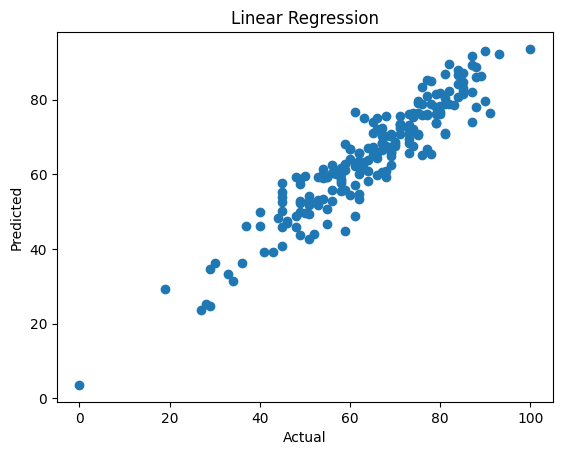

In [79]:
#plot_pred and y_test
plt.scatter(y_test, y_pred);
plt.xlabel("Actual");
plt.ylabel("Predicted");
plt.title("Linear Regression");
plt.show();

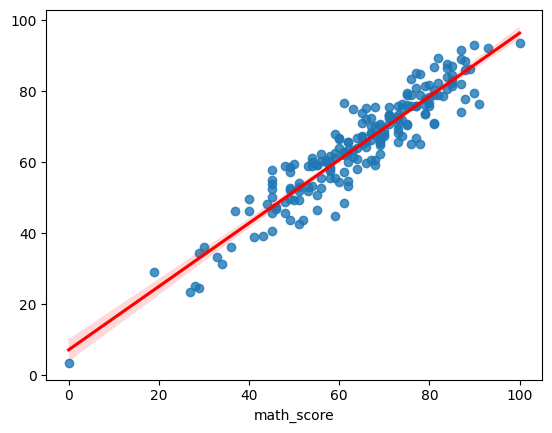

In [80]:
sns.regplot(x=y_test, y=y_pred, line_kws={"color": "red"});

In [81]:
#diffrance between actual and predicted values
pred_diff =pd.DataFrame({"Actual": y_test, "Predicted": y_pred, "Difference": y_test - y_pred})
pred_diff.head(10)

,Actual,Predicted,Difference
521,91,76.4375,14.5625
737,53,59.1250,-6.1250
740,80,76.7500,3.2500
660,74,76.5000,-2.5000
411,84,87.8125,-3.8125
678,81,78.9375,2.0625
626,69,64.8750,4.1250
513,54,53.2500,0.7500
859,87,74.0625,12.9375
136,51,49.3125,1.6875
